# 01 — Exploratory Data Analysis: MERGE Audio Balanced

This notebook documents the analysis behind every data-related decision in the thesis. Each section states its **purpose**, runs the analysis, saves the figures and tables to `results/eda/`, and ends with the **findings** and the **decision** they support. Decisions are recorded in `docs/DECISIONS.md` with a reference to the section that justifies them.

**Inputs** (produced earlier in the pipeline):
- `data/raw/MERGE_Audio_Balanced/merge_audio_balanced_metadata.csv` and `merge_audio_balanced_av_values.csv` — official dataset files
- `data/raw/MERGE_Audio_Balanced/tvt_dataframes/tvt_70_15_15/` — official train/validation/test split
- `data/features/features_librosa.csv` — output of `src/features.py`

**Rule used throughout:** descriptive analyses of labels and metadata use the whole dataset; any analysis of audio features that could influence modelling choices uses the **training set only**, so that no information from the validation or test sets leaks into model design.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATASET = ROOT / "data" / "raw" / "MERGE_Audio_Balanced"
SPLIT_DIR = DATASET / "tvt_dataframes" / "tvt_70_15_15"
FEATURES = ROOT / "data" / "features" / "features_librosa.csv"
OUT = ROOT / "results" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
COLORS = {"Q1": "#E69F00", "Q2": "#D55E00", "Q3": "#0072B2", "Q4": "#009E73"}
NAMES = {"Q1": "Q1 happy/excited", "Q2": "Q2 angry/tense", "Q3": "Q3 sad", "Q4": "Q4 calm/relaxed"}
NON_FEATURES = ["Song", "Quadrant", "duration_loaded"]
summary = {}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()


meta = pd.read_csv(DATASET / "merge_audio_balanced_metadata.csv")
av = pd.read_csv(DATASET / "merge_audio_balanced_av_values.csv")
feats = pd.read_csv(FEATURES)
split = pd.concat(
    [pd.read_csv(SPLIT_DIR / f"tvt_70_15_15_{p}_audio_balanced.csv").assign(Split=p) for p in ["train", "validate", "test"]],
    ignore_index=True,
)
df = meta.merge(av, on="Song").merge(split[["Song", "Split"]], on="Song", how="left")
feature_cols = [c for c in feats.columns if c not in NON_FEATURES]
print(f"metadata {meta.shape}, av {av.shape}, features {feats.shape}, split {split.shape}")
print(f"audio features: {len(feature_cols)}")

metadata (3232, 26), av (3232, 3), features (3232, 136), split (3232, 3)
audio features: 133


## 1. Dataset composition

**Purpose:** confirm the size of the dataset, the class balance and the origin of the samples, and check the metadata for missing values.

In [2]:
composition = pd.DataFrame({
    "samples": df["Quadrant"].value_counts().reindex(QUADRANTS),
    "from AllMusic (MT ids)": df[df["Song"].str.startswith("MT")]["Quadrant"].value_counts().reindex(QUADRANTS),
    "from private collections (A ids)": df[df["Song"].str.startswith("A")]["Quadrant"].value_counts().reindex(QUADRANTS),
})
composition.loc["total"] = composition.sum()
composition.to_csv(OUT / "01_composition.csv")
display(composition)

split_table = pd.crosstab(df["Split"], df["Quadrant"]).reindex(["train", "validate", "test"])
split_table["total"] = split_table.sum(axis=1)
split_table.to_csv(OUT / "01_official_split_counts.csv")
display(split_table)

missing_meta = meta[["Song", "Quadrant", "Artist", "Title", "Genres", "ActualYear"]].isna().sum()
display(missing_meta.to_frame("missing values"))
summary["n_samples"] = int(len(df))
summary["per_quadrant"] = df["Quadrant"].value_counts().reindex(QUADRANTS).to_dict()
summary["missing_artist"] = int(meta["Artist"].isna().sum())

,samples,from AllMusic (MT ids),from private collections (A ids)
Quadrant,,,
Q1,808,771,37
Q2,808,771,37
Q3,808,778,30
Q4,808,779,29
total,3232,3099,133


Quadrant,Q1,Q2,Q3,Q4,total
Split,,,,,
train,566,566,566,566,2264
validate,121,121,121,121,484
test,121,121,121,121,484


,missing values
Song,0
Quadrant,0
Artist,3
Title,0
Genres,32
ActualYear,151


**Findings.** All 3,232 clips are present, with exactly 808 per quadrant; 3,099 come from AllMusic and 133 from private collections. The official 70-15-15 split is perfectly balanced (566/121/121 per quadrant). Three songs have no artist, 32 no genre and 151 no release year; none of these fields is used as a model input.

**Decision supported:** D02 — no class rebalancing is needed.

## 2. Emotion labels in the valence–arousal plane

**Purpose:** understand how the quadrant labels relate to the continuous arousal and valence values, and how many samples lie close to a quadrant boundary. Samples near a boundary are inherently ambiguous and limit the accuracy any model can reach.

Quadrant label equals the AV values thresholded at 0.5 for 100.00% of samples


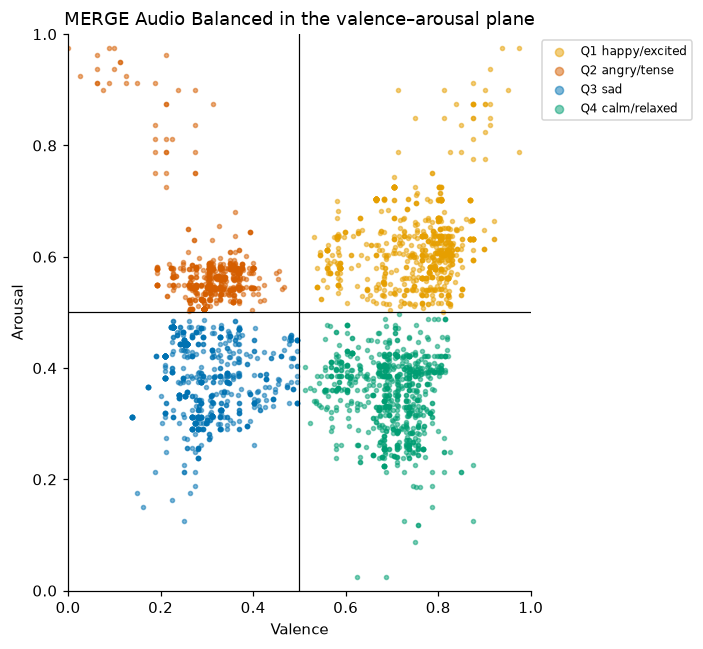

Samples within 0.05 of a quadrant boundary: 25.4%


,share near boundary
Quadrant,
Q1,0.148515
Q2,0.570545
Q3,0.231436
Q4,0.066832


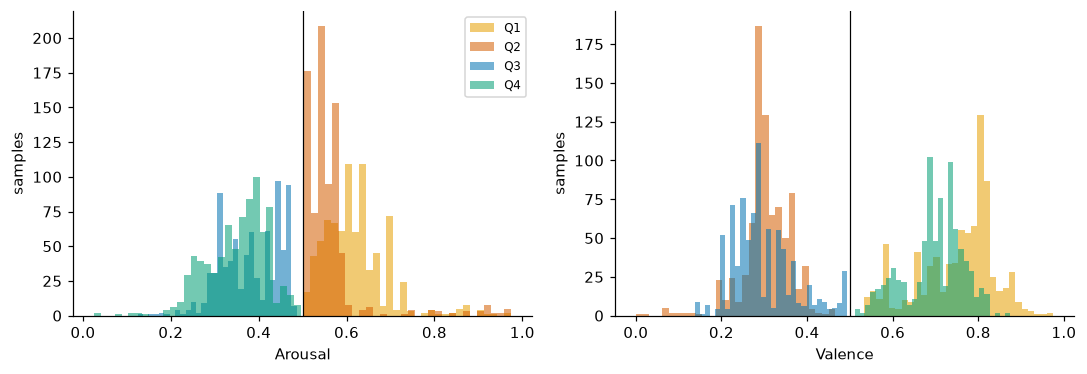

In [3]:
def quadrant_from_av(a, v):
    return np.where(a >= 0.5, np.where(v >= 0.5, "Q1", "Q2"), np.where(v >= 0.5, "Q4", "Q3"))


df["Quadrant_from_AV"] = quadrant_from_av(df["Arousal"], df["Valence"])
agreement = (df["Quadrant_from_AV"] == df["Quadrant"]).mean()
print(f"Quadrant label equals the AV values thresholded at 0.5 for {agreement:.2%} of samples")

fig, ax = plt.subplots(figsize=(6.5, 6))
for q in QUADRANTS:
    s = df[df["Quadrant"] == q]
    ax.scatter(s["Valence"], s["Arousal"], s=7, alpha=0.5, color=COLORS[q], label=NAMES[q])
ax.axhline(0.5, color="black", lw=0.8)
ax.axvline(0.5, color="black", lw=0.8)
ax.set_xlabel("Valence")
ax.set_ylabel("Arousal")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("MERGE Audio Balanced in the valence–arousal plane")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, markerscale=2)
save(fig, "02_valence_arousal_scatter")

margin = 0.05
df["near_boundary"] = ((df["Arousal"] - 0.5).abs() < margin) | ((df["Valence"] - 0.5).abs() < margin)
near = df.groupby("Quadrant")["near_boundary"].mean().reindex(QUADRANTS)
print(f"Samples within {margin} of a quadrant boundary: {df['near_boundary'].mean():.1%}")
display(near.rename("share near boundary").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["Arousal", "Valence"]):
    for q in QUADRANTS:
        ax.hist(df.loc[df["Quadrant"] == q, col], bins=30, alpha=0.55, color=COLORS[q], label=q)
    ax.axvline(0.5, color="black", lw=0.8)
    ax.set_xlabel(col)
    ax.set_ylabel("samples")
axes[0].legend(fontsize=8)
save(fig, "02_arousal_valence_histograms")

summary["label_av_agreement"] = round(float(agreement), 4)
summary["share_near_boundary_0.05"] = round(float(df["near_boundary"].mean()), 4)
summary["av_std"] = {"arousal": round(float(df["Arousal"].std()), 4), "valence": round(float(df["Valence"].std()), 4)}

**Findings.** The quadrant label is exactly the arousal and valence values thresholded at 0.5 (100% agreement), so the four classes are a discretisation of the continuous plane. About a quarter of all samples lie within 0.05 of a boundary. This share differs strongly by quadrant: most Q2 samples have arousal only slightly above 0.5, so Q2 is concentrated near the Q2/Q3 border, while Q4 lies far from the boundaries. Valence varies more than arousal across the dataset.

**Decision supported:** D03 — the quadrant label is used as given; the proximity of many samples to a boundary is reported as a limitation that caps the achievable accuracy.

## 3. Clip duration

**Purpose:** the dataset provides 30-second excerpts. `src/features.py` records the loaded duration of every clip. This section identifies clips that are substantially shorter, because they carry less information and, for the CNN, require padding to a fixed length.

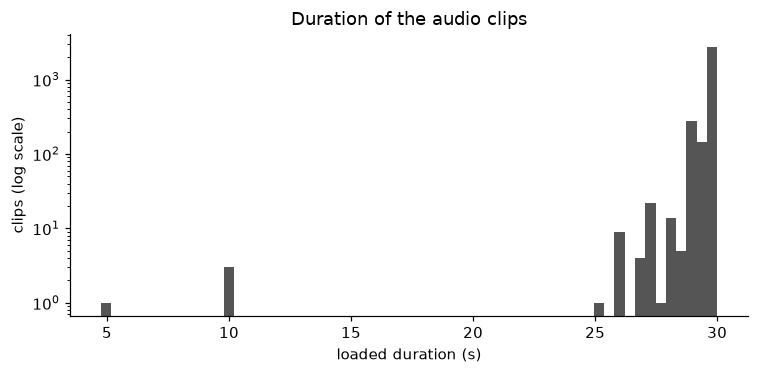

,clips
duration_loaded,
< 15 s,4
15–29 s,68
29–29.9 s,785
≥ 29.9 s,2375


,Song,Quadrant,duration_loaded
722,MT0002054074,Q4,4.752018
1539,MT0006678796,Q4,10.080000
2550,MT0013621344,Q1,10.080000
2585,MT0013914319,Q1,10.080000


In [4]:
dur = feats[["Song", "Quadrant", "duration_loaded"]].copy()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(dur["duration_loaded"], bins=60, color="#555555")
ax.set_yscale("log")
ax.set_xlabel("loaded duration (s)")
ax.set_ylabel("clips (log scale)")
ax.set_title("Duration of the audio clips")
save(fig, "03_clip_duration")

bins = pd.cut(dur["duration_loaded"], [0, 15, 29, 29.9, 31], labels=["< 15 s", "15–29 s", "29–29.9 s", "≥ 29.9 s"])
display(bins.value_counts().sort_index().rename("clips").to_frame())
short = dur[dur["duration_loaded"] < 15].sort_values("duration_loaded")
short.to_csv(OUT / "03_very_short_clips.csv", index=False)
display(short)
summary["clips_under_29s"] = int((dur["duration_loaded"] < 29).sum())
summary["clips_under_15s"] = short["Song"].tolist()

**Findings.** 3,160 of 3,232 clips last at least 29 s. 68 clips last between 15 and 29 s and four clips are much shorter (one of 4.8 s and three of 10.1 s), all of them in the training set.

**Decision supported:** D04 — see Section 10: these clips are not feature outliers, so they are kept.

## 4. Duplicate recordings

**Purpose:** detect the same song stored under different IDs (same artist and title). A duplicate split across training and evaluation sets would let a model be evaluated on a recording it was trained on.

In [5]:
dup = df[df.duplicated(["Artist", "Title"], keep=False)].sort_values(["Artist", "Title"])
dup_table = dup[["Song", "Artist", "Title", "Quadrant", "Arousal", "Valence", "Split"]]
dup_table.to_csv(OUT / "04_duplicates.csv", index=False)
display(dup_table)

pairs = dup.groupby(["Artist", "Title"])["Split"].apply(lambda s: " / ".join(sorted(s)))
display(pairs.value_counts().rename("pairs").to_frame())
same_label = dup.groupby(["Artist", "Title"])["Quadrant"].nunique().eq(1).all()
print(f"Duplicate pairs: {len(pairs)}; all pairs share the same quadrant: {same_label}")
summary["duplicate_pairs"] = int(len(pairs))
summary["duplicate_pairs_by_split"] = pairs.value_counts().to_dict()

,Song,Artist,Title,Quadrant,Arousal,Valence,Split
42,A066-140,Enya,Journey of the Angels,Q4,0.025000,0.687500,train
2010,MT0009795009,Enya,Journey of the Angels,Q4,0.335625,0.631250,validate
1084,MT0003965796,Gloria Estefan,Rhythm Is Gonna Get You,Q1,0.595000,0.800000,test
1626,MT0007132421,Gloria Estefan,Rhythm Is Gonna Get You,Q1,0.631250,0.821250,validate
77,A114-120,Luther Vandross,Never Too Much,Q1,0.850000,0.875000,train
2326,MT0011933875,Luther Vandross,Never Too Much,Q1,0.515000,0.777500,validate
72,A105-117,Prince,Kiss,Q1,0.850000,0.812500,train
779,MT0002343207,Prince,Kiss,Q1,0.596250,0.791875,train
4,A005,Prince,U Got the Look,Q1,0.787500,0.712500,validate
1166,MT0004444570,Prince,U Got the Look,Q1,0.521250,0.658125,train


,pairs
Split,
train / validate,3
train / train,2
test / validate,1


Duplicate pairs: 6; all pairs share the same quadrant: True


**Findings.** Six songs appear twice under different IDs. Each pair shares the same quadrant, but the arousal and valence values within a pair differ (for example, the two copies of Enya's *Journey of the Angels* have arousal 0.03 and 0.34), which shows that the continuous annotations carry noise. In the official split, no pair is divided between training and test; three pairs are divided between training and validation and one between test and validation.

**Decision supported:** D05 — duplicates are kept in the official protocol for comparability with the published results and are reported; in the artist-grouped protocol both copies fall in the same set automatically.

## 5. Artists

**Purpose:** measure how strongly the artist determines the quadrant, and how many test songs come from artists also present in the training set. If most songs of an artist share a quadrant, a model can learn to recognise the artist's sound instead of the emotion, and an evaluation where the same artists appear in training and test overestimates generalisation to new music (the *artist effect*).

Distinct artists: 1620
Artists with one song: 1043, with more than one: 577 (covering 2186 songs)
Songs in their artist's majority quadrant: 85.0%
Multi-song artists whose songs all share one quadrant: 380 of 577


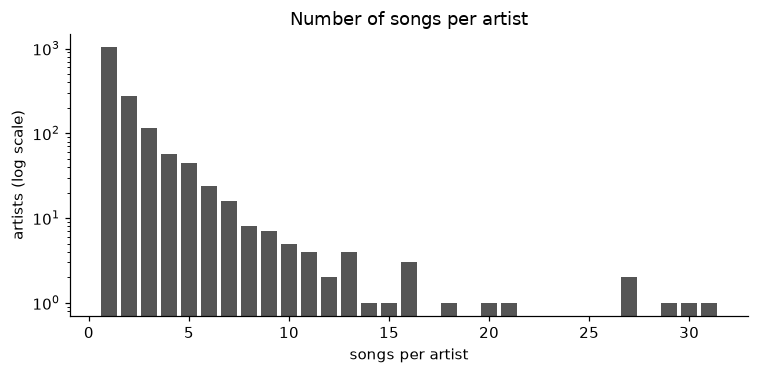

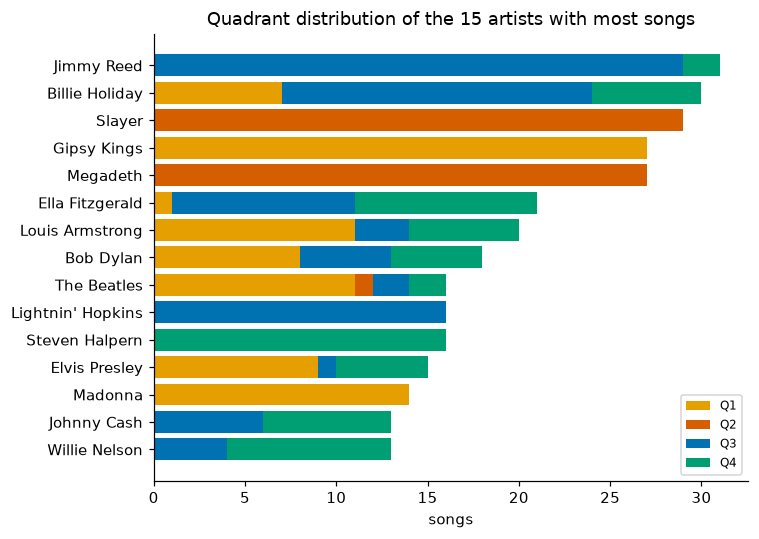

,songs,artist_in_train,share
validate,484.0,307.0,0.6343
test,484.0,320.0,0.6612


In [6]:
known = df.dropna(subset=["Artist"])
songs_per_artist = known["Artist"].value_counts()
print(f"Distinct artists: {known['Artist'].nunique()}")
print(f"Artists with one song: {(songs_per_artist == 1).sum()}, with more than one: {(songs_per_artist > 1).sum()} "
      f"(covering {songs_per_artist[songs_per_artist > 1].sum()} songs)")

multi = known[known["Artist"].isin(songs_per_artist[songs_per_artist > 1].index)]
majority = multi.groupby("Artist")["Quadrant"].agg(lambda s: s.value_counts().iloc[0])
purity = majority.sum() / len(multi)
single_quadrant = (multi.groupby("Artist")["Quadrant"].nunique() == 1).sum()
print(f"Songs in their artist's majority quadrant: {purity:.1%}")
print(f"Multi-song artists whose songs all share one quadrant: {single_quadrant} of {multi['Artist'].nunique()}")

fig, ax = plt.subplots(figsize=(7, 3.5))
counts = songs_per_artist.value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#555555")
ax.set_yscale("log")
ax.set_xlabel("songs per artist")
ax.set_ylabel("artists (log scale)")
ax.set_title("Number of songs per artist")
save(fig, "05_songs_per_artist")

top = songs_per_artist.head(15).index
top_table = pd.crosstab(known[known["Artist"].isin(top)]["Artist"], known["Quadrant"]).reindex(top)[QUADRANTS]
top_table.to_csv(OUT / "05_top_artists_by_quadrant.csv")
fig, ax = plt.subplots(figsize=(7, 5))
left = np.zeros(len(top_table))
for q in QUADRANTS:
    ax.barh(top_table.index, top_table[q], left=left, color=COLORS[q], label=q)
    left += top_table[q].values
ax.invert_yaxis()
ax.set_xlabel("songs")
ax.set_title("Quadrant distribution of the 15 artists with most songs")
ax.legend(fontsize=8)
save(fig, "05_top_artists_by_quadrant")

train_artists = set(df.loc[df["Split"] == "train", "Artist"].dropna())
overlap = {}
for part in ["validate", "test"]:
    s = df[df["Split"] == part]
    seen = s["Artist"].isin(train_artists)
    overlap[part] = {"songs": int(len(s)), "artist_in_train": int(seen.sum()), "share": round(float(seen.mean()), 4)}
overlap_table = pd.DataFrame(overlap).T
overlap_table.to_csv(OUT / "05_artist_overlap_official_split.csv")
display(overlap_table)

summary["distinct_artists"] = int(known["Artist"].nunique())
summary["artist_majority_quadrant_share"] = round(float(purity), 4)
summary["official_split_artist_overlap"] = overlap

**Findings.** The 3,232 songs come from 1,620 artists; 577 artists contribute more than one song (2,186 songs in total). For those artists, 85% of their songs fall in the artist's most frequent quadrant, and 380 of the 577 artists have all their songs in a single quadrant. In the official split, 66% of test songs and 63% of validation songs come from artists that also appear in the training set.

**Decision supported:** D06 — in addition to the official split, an artist-grouped split is created (`src/splits.py`) in which every artist appears in only one set, to measure how much of each model's performance depends on recognising artists.

## 6. Genres

**Purpose:** check whether musical genre is associated with the quadrant. A strong association is a second shortcut a model can exploit, and it explains why certain quadrants are acoustically easier to separate.

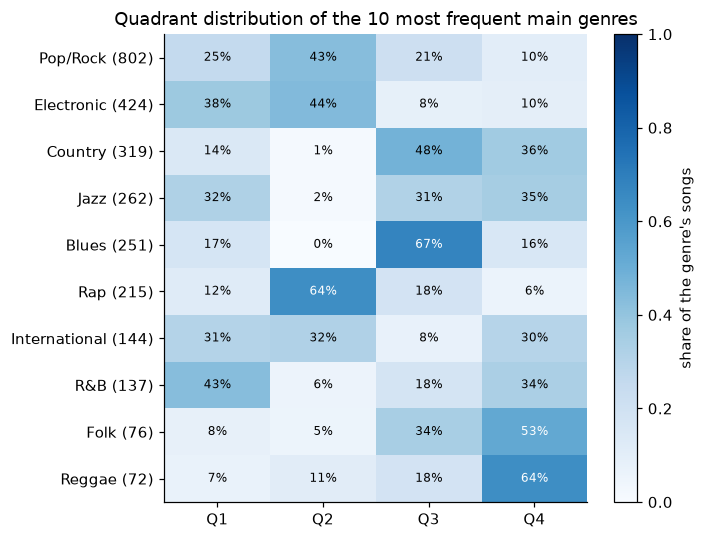

Chi-square test genre × quadrant: chi2=1159.9, dof=27, p=2.87e-227, Cramér's V=0.38


In [7]:
df["MainGenre"] = df["Genres"].fillna("Unknown").str.split(",").str[0]
main_genres = df["MainGenre"].value_counts().head(10).index
genre_table = pd.crosstab(df["MainGenre"], df["Quadrant"]).loc[main_genres, QUADRANTS]
genre_share = genre_table.div(genre_table.sum(axis=1), axis=0)
genre_table.to_csv(OUT / "06_genre_by_quadrant.csv")

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(genre_share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), QUADRANTS)
ax.set_yticks(range(len(main_genres)), [f"{g} ({n})" for g, n in zip(main_genres, genre_table.sum(axis=1))])
for i in range(len(main_genres)):
    for j in range(4):
        ax.text(j, i, f"{genre_share.values[i, j]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if genre_share.values[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, label="share of the genre's songs")
ax.set_title("Quadrant distribution of the 10 most frequent main genres")
save(fig, "06_genre_by_quadrant")

chi2, p, dof, _ = stats.chi2_contingency(genre_table)
cramers_v = np.sqrt(chi2 / (genre_table.values.sum() * (min(genre_table.shape) - 1)))
print(f"Chi-square test genre × quadrant: chi2={chi2:.1f}, dof={dof}, p={p:.2e}, Cramér's V={cramers_v:.2f}")
summary["genre_quadrant_cramers_v"] = round(float(cramers_v), 3)

**Findings.** Genre and quadrant are strongly associated (chi-square test p < 0.001, Cramér's V ≈ 0.38). Rap is mostly Q2, Blues mostly Q3, Reggae and Folk mostly Q4, and Country, Jazz and Blues almost never Q2. This is a second shortcut, closely linked to the artist effect, since an artist usually stays within one genre.

**Decision supported:** D06 — the artist-grouped split also limits this shortcut; genre is not used as an input.

## 7. Audio features — quality checks (training set)

**Purpose:** verify that the extracted features contain no missing or infinite values and no constant columns, and look at their ranges. From this section onward only the **training set** of the official split is used.

In [8]:
data = feats.merge(split[["Song", "Split"]], on="Song")
train = data[data["Split"] == "train"].reset_index(drop=True).copy()
X = train[feature_cols]
checks = {
    "training samples": len(train),
    "features": len(feature_cols),
    "missing values": int(X.isna().sum().sum()),
    "infinite values": int(np.isinf(X.to_numpy()).sum()),
    "constant features": int((X.std() == 0).sum()),
}
display(pd.Series(checks).to_frame("value"))
desc = X.describe().T
desc.to_csv(OUT / "07_feature_description_train.csv")
display(desc.head(12))
print("Ratio between the largest and smallest feature standard deviation:", f"{desc['std'].max() / desc['std'].min():.1e}")

,value
training samples,2264
features,133
missing values,0
infinite values,0
constant features,0


,count,mean,std,min,25%,50%,75%,max
mfcc_01_mean,2264.0,-128.530357,91.773658,-475.806702,-191.621002,-123.443806,-59.484455,96.345772
mfcc_01_std,2264.0,69.710188,17.195536,16.358799,57.568278,69.014732,80.071064,147.017700
mfcc_02_mean,2264.0,103.278984,33.627615,22.478930,76.651459,100.988682,125.711206,219.256409
mfcc_02_std,2264.0,25.712102,7.708472,9.863748,20.050632,25.130196,30.663377,69.681236
mfcc_03_mean,2264.0,-9.728333,25.605614,-100.953293,-24.017669,-8.367218,6.420709,97.729492
mfcc_03_std,2264.0,20.824193,6.241672,7.600849,16.422873,20.066298,24.442486,51.224953
mfcc_04_mean,2264.0,34.897826,17.169943,-27.094030,23.808668,31.995253,43.927665,99.099762
mfcc_04_std,2264.0,15.291558,3.820465,7.361557,12.557011,14.918587,17.497981,37.614216
mfcc_05_mean,2264.0,-1.725300,14.089935,-62.277447,-8.547109,1.274212,7.439021,55.478100
mfcc_05_std,2264.0,13.411132,3.728790,5.623724,10.581320,12.949113,15.728314,32.503677


Ratio between the largest and smallest feature standard deviation: 2.0e+05


**Findings.** The 133 features of the 2,264 training clips contain no missing or infinite values and no constant columns. Their scales differ by about five orders of magnitude (for example, spectral centroid in thousands of Hz and spectral flatness close to zero).

**Decision supported:** D07 — features are standardised before the SVM (scaler fitted on the training set only, inside the model pipeline); Random Forest does not need scaling.

## 8. Which features separate the quadrants (training set)

**Purpose:** quantify, for each feature, how different its distribution is across the four quadrants, using the Kruskal–Wallis test (a non-parametric alternative to one-way ANOVA that does not assume normal distributions). The effect size ε² (epsilon-squared) ranges from 0 (no difference) to 1. The section also checks the two separation problems separately: arousal (Q1+Q2 vs Q3+Q4) and, inside the low-arousal half, Q3 vs Q4.

In [9]:
def kruskal_eps(frame, labels):
    rows = []
    groups = frame.groupby(labels)
    n = len(frame)
    k = labels.nunique()
    for col in feature_cols:
        h, p = stats.kruskal(*[g[col].to_numpy() for _, g in groups])
        rows.append({"feature": col, "H": h, "p": p, "epsilon2": (h - k + 1) / (n - k)})
    return pd.DataFrame(rows).sort_values("epsilon2", ascending=False).reset_index(drop=True)


ranking = kruskal_eps(train, train["Quadrant"])
ranking.to_csv(OUT / "08_feature_ranking_kruskal_train.csv", index=False)
display(ranking.head(15))
print(f"Features with p < 0.001: {(ranking['p'] < 0.001).sum()} of {len(ranking)}")

train = train.copy()
train["arousal_half"] = np.where(train["Quadrant"].isin(["Q1", "Q2"]), "high", "low")
low = train[train["arousal_half"] == "low"]
ranking_arousal = kruskal_eps(train, train["arousal_half"])
ranking_q3q4 = kruskal_eps(low, low["Quadrant"])
comparison = pd.DataFrame({
    "best feature: high vs low arousal": ranking_arousal.head(5)["feature"].values,
    "ε² (arousal)": ranking_arousal.head(5)["epsilon2"].round(3).values,
    "best feature: Q3 vs Q4": ranking_q3q4.head(5)["feature"].values,
    "ε² (Q3 vs Q4)": ranking_q3q4.head(5)["epsilon2"].round(3).values,
})
comparison.to_csv(OUT / "08_arousal_vs_q3q4_separation.csv", index=False)
display(comparison)

summary["top_features_kruskal"] = ranking.head(10)["feature"].tolist()
summary["max_epsilon2_arousal"] = round(float(ranking_arousal["epsilon2"].max()), 3)
summary["max_epsilon2_q3_vs_q4"] = round(float(ranking_q3q4["epsilon2"].max()), 3)

,feature,H,p,epsilon2
0,spectral_contrast_03_mean,1350.596277,1.546211e-292,0.596282
1,spectral_contrast_02_mean,1269.514091,6.062034e-275,0.560404
2,spectral_contrast_04_mean,1211.801756,2.016535e-262,0.534868
3,mfcc_01_mean,1126.867962,5.395014e-244,0.497287
4,spectral_contrast_05_mean,1063.199128,3.506696e-230,0.469115
5,zcr_mean,954.597509,1.270835e-206,0.421061
6,chroma_04_mean,823.977185,2.729301e-178,0.363264
7,spectral_centroid_mean,815.556322,1.829757e-176,0.359538
8,chroma_09_mean,815.251197,2.130931e-176,0.359403
9,spectral_contrast_05_std,798.308853,1.006940e-172,0.351907


Features with p < 0.001: 120 of 133


,best feature: high vs low arousal,ε² (arousal),best feature: Q3 vs Q4,ε² (Q3 vs Q4)
0,spectral_contrast_02_mean,0.513,mfcc_03_std,0.025
1,spectral_contrast_03_mean,0.512,mfcc_03_mean,0.024
2,mfcc_01_mean,0.430,mfcc_13_std,0.019
3,spectral_contrast_04_mean,0.427,spectral_contrast_03_mean,0.016
4,zcr_mean,0.390,mfcc_12_std,0.016


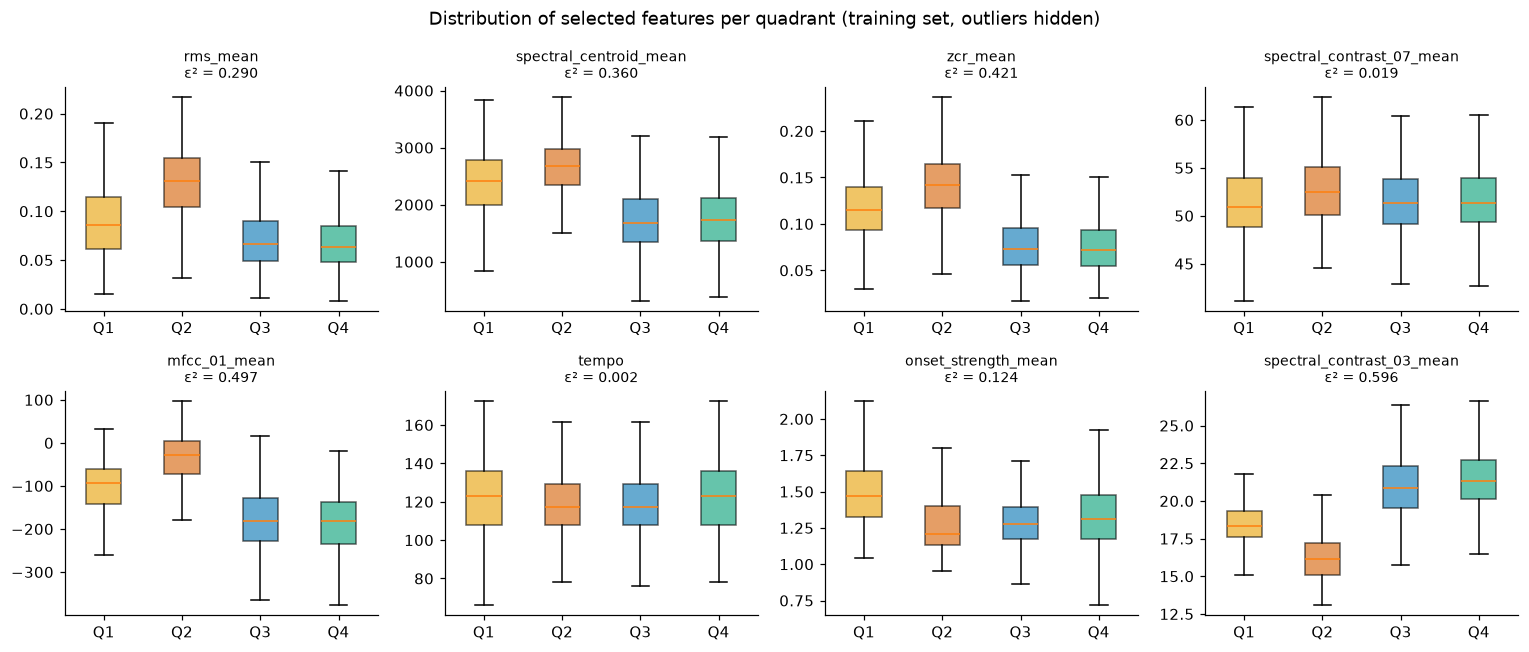

In [10]:
show = ["rms_mean", "spectral_centroid_mean", "zcr_mean", "spectral_contrast_07_mean", "mfcc_01_mean", "chroma_std_mean", "tempo", "onset_strength_mean"]
show = [c for c in show if c in feature_cols]
for extra in ranking["feature"]:
    if len(show) >= 8:
        break
    if extra not in show:
        show.append(extra)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, show):
    parts = [train.loc[train["Quadrant"] == q, col] for q in QUADRANTS]
    bp = ax.boxplot(parts, tick_labels=QUADRANTS, showfliers=False, patch_artist=True)
    for patch, q in zip(bp["boxes"], QUADRANTS):
        patch.set_facecolor(COLORS[q])
        patch.set_alpha(0.6)
    eps = ranking.set_index("feature").loc[col, "epsilon2"]
    ax.set_title(f"{col}\nε² = {eps:.3f}", fontsize=9)
fig.suptitle("Distribution of selected features per quadrant (training set, outliers hidden)")
save(fig, "08_feature_boxplots")

**Findings.** 120 of the 133 features differ significantly across quadrants (p < 0.001). The strongest are spectral contrast in the low and middle bands, the first MFCC (overall energy and brightness), zero-crossing rate and several chroma means. Tempo shows almost no difference (ε² ≈ 0.002). The decisive observation is the comparison of the two sub-problems: the best feature separates high from low arousal with ε² ≈ 0.51, but the best feature separates Q3 from Q4 with only ε² ≈ 0.03. Arousal is well captured by these features; the valence difference between sad and calm music is barely captured at all.

**Decision supported:** D08 — all 133 features are kept as model input (no univariate feature selection); a Q3/Q4 confusion is expected and will be analysed explicitly in the results.

## 9. Correlation between features (training set)

**Purpose:** identify redundant features. Highly correlated features carry the same information; this matters for interpreting feature importances and for deciding whether feature selection is needed.

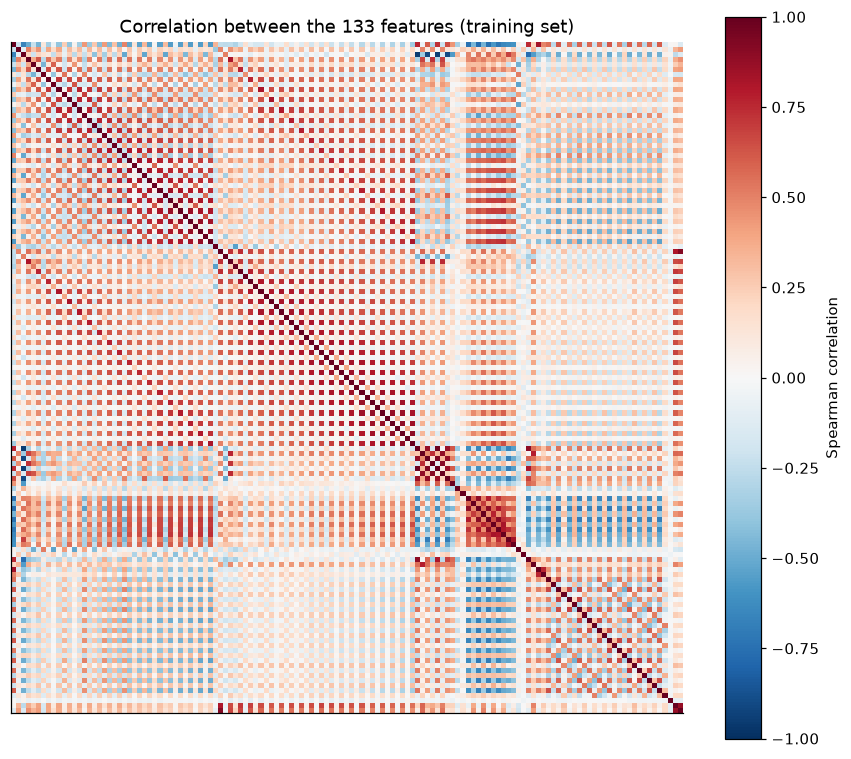

Feature pairs with |correlation| > 0.9: 10


,feature_a,feature_b,spearman
0,spectral_centroid_mean,spectral_rolloff_mean,0.977335
1,mfcc_02_mean,spectral_centroid_mean,-0.945455
2,mfcc_02_mean,spectral_rolloff_mean,-0.940302
3,spectral_bandwidth_mean,spectral_rolloff_mean,0.932864
4,mfcc_delta_01_std,onset_strength_std,0.917700
5,mfcc_02_mean,spectral_bandwidth_mean,-0.908376
6,spectral_bandwidth_std,spectral_rolloff_std,0.907190
7,mfcc_02_mean,spectral_flatness_mean,-0.906065
8,spectral_contrast_03_mean,spectral_contrast_04_mean,0.903428
9,spectral_contrast_04_mean,spectral_contrast_05_mean,0.903027


In [11]:
corr = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks([])
ax.set_yticks([])
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title(f"Correlation between the {len(feature_cols)} features (training set)")
save(fig, "09_feature_correlation")

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = upper[upper.abs() > 0.9].sort_values(key=np.abs, ascending=False).rename("spearman").reset_index()
strong.columns = ["feature_a", "feature_b", "spearman"]
strong.to_csv(OUT / "09_strongly_correlated_pairs.csv", index=False)
print(f"Feature pairs with |correlation| > 0.9: {len(strong)}")
display(strong.head(15))
summary["pairs_abs_corr_over_0.9"] = int(len(strong))

**Findings.** Ten feature pairs have an absolute Spearman correlation above 0.9, mostly among spectral centroid, rolloff, bandwidth and the second MFCC, which all describe the brightness of the sound. The remaining features are much less redundant.

**Decision supported:** D08 — redundant features are kept, because neither SVM with an RBF kernel nor Random Forest is harmed by moderate redundancy; it is taken into account when interpreting Random Forest feature importances, which split importance among correlated features.

## 10. Outliers (training set)

**Purpose:** find clips whose feature values are extreme compared with the rest of the training set, and check whether they coincide with the very short clips from Section 3. A robust z-score (based on the median and the median absolute deviation) is used because it is not distorted by the outliers themselves.

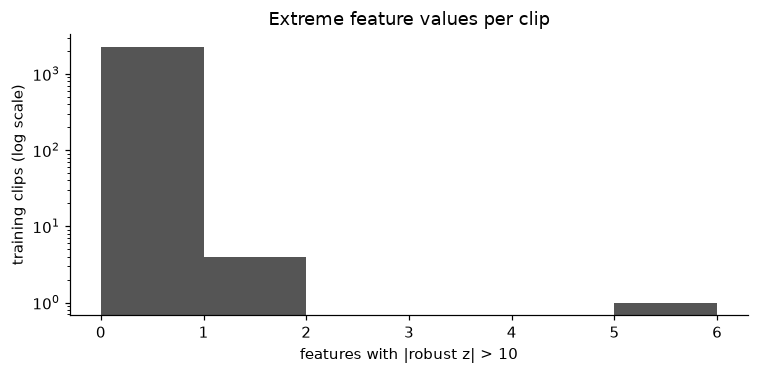

Training clips with at least 10 extreme features: 0


,Song,Quadrant,duration_loaded,extreme_features,Artist,Title


Very short clips in the training set: ['MT0002054074', 'MT0006678796', 'MT0013621344', 'MT0013914319']
Of these, flagged as outliers: []


In [12]:
med = X.median()
mad = (X - med).abs().median().replace(0, np.nan)
robust_z = 0.6745 * (X - med) / mad
extreme_count = (robust_z.abs() > 10).sum(axis=1)
train = train.copy()
train["extreme_features"] = extreme_count

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(extreme_count, bins=range(0, int(extreme_count.max()) + 2), color="#555555")
ax.set_yscale("log")
ax.set_xlabel("features with |robust z| > 10")
ax.set_ylabel("training clips (log scale)")
ax.set_title("Extreme feature values per clip")
save(fig, "10_outliers")

outliers = train.loc[extreme_count >= 10, ["Song", "Quadrant", "duration_loaded", "extreme_features"]].sort_values("extreme_features", ascending=False)
outliers = outliers.merge(meta[["Song", "Artist", "Title"]], on="Song")
outliers.to_csv(OUT / "10_outlier_clips_train.csv", index=False)
print(f"Training clips with at least 10 extreme features: {len(outliers)}")
display(outliers)
short_in_train = set(short["Song"]) & set(train["Song"])
print("Very short clips in the training set:", sorted(short_in_train))
print("Of these, flagged as outliers:", sorted(short_in_train & set(outliers["Song"])))
summary["train_outlier_clips"] = outliers["Song"].tolist()

**Findings.** No training clip has ten or more extreme feature values (|robust z| > 10). The four very short clips are not flagged, so their aggregated features are within the normal range.

**Decision supported:** D04 — no clips are removed as outliers; the very short clips are kept for the feature-based models and will be padded for the CNN.

## 11. Projection to two dimensions (training set)

**Purpose:** visualise whether the quadrants form separable groups before any model is trained. PCA (principal component analysis) finds the directions of largest variance in the standardised features; if the quadrants overlap in this projection, a linear model alone is unlikely to separate them well.

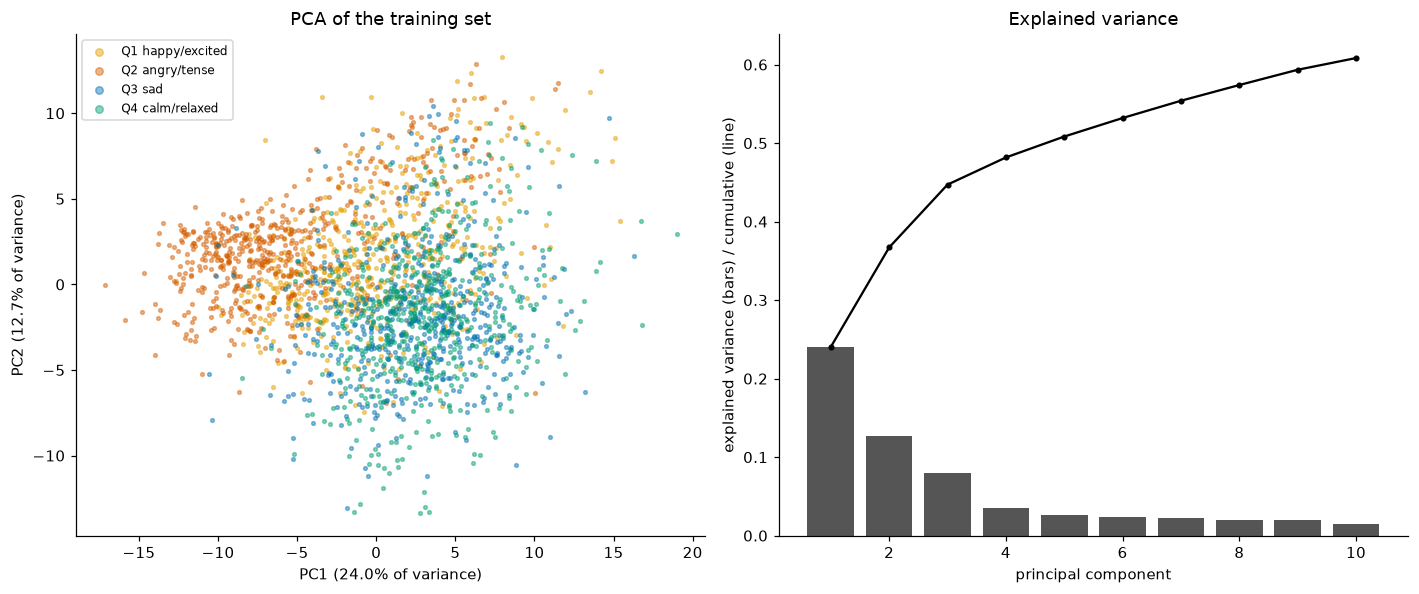

,Spearman correlation
PC1 vs arousal,-0.348
PC1 vs valence,0.162
PC2 vs arousal,0.410
PC2 vs valence,0.035


In [13]:
Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=10, random_state=42).fit(Z)
P = pca.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for q in QUADRANTS:
    m = train["Quadrant"] == q
    axes[0].scatter(P[m, 0], P[m, 1], s=6, alpha=0.45, color=COLORS[q], label=NAMES[q])
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
axes[0].set_title("PCA of the training set")
axes[0].legend(fontsize=8, markerscale=2)
axes[1].bar(range(1, 11), pca.explained_variance_ratio_, color="#555555")
axes[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_), color="black", marker="o", ms=3)
axes[1].set_xlabel("principal component")
axes[1].set_ylabel("explained variance (bars) / cumulative (line)")
axes[1].set_title("Explained variance")
save(fig, "11_pca")

pc1 = pd.Series(P[:, 0])
pc_corr = {
    "PC1 vs arousal": stats.spearmanr(P[:, 0], train.merge(av, on="Song")["Arousal"])[0],
    "PC1 vs valence": stats.spearmanr(P[:, 0], train.merge(av, on="Song")["Valence"])[0],
    "PC2 vs arousal": stats.spearmanr(P[:, 1], train.merge(av, on="Song")["Arousal"])[0],
    "PC2 vs valence": stats.spearmanr(P[:, 1], train.merge(av, on="Song")["Valence"])[0],
}
display(pd.Series(pc_corr).round(3).to_frame("Spearman correlation"))
summary["pca_first_two_variance"] = round(float(pca.explained_variance_ratio_[:2].sum()), 4)
summary["pca_axis_correlations"] = {k: round(float(v), 3) for k, v in pc_corr.items()}

**Findings.** The first two principal components explain about 37% of the variance. In the projection, Q2 forms a recognisable region, Q1 partly overlaps with it, and Q3 and Q4 overlap almost completely. The first two components correlate moderately with arousal and only weakly with valence, which confirms Section 8: the dominant variation in these features follows arousal.

**Decision supported:** D08 — a non-linear classifier (RBF SVM, Random Forest, CNN) is needed; separating Q3 from Q4 is the main difficulty for every model.

## 12. Summary of the analysis

All numbers below are written to `results/eda/summary.json`, which `docs/DECISIONS.md` references.

In [14]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(summary, indent=2, ensure_ascii=False, default=str))

{
  "n_samples": 3232,
  "per_quadrant": {
    "Q1": 808,
    "Q2": 808,
    "Q3": 808,
    "Q4": 808
  },
  "missing_artist": 3,
  "label_av_agreement": 1.0,
  "share_near_boundary_0.05": 0.2543,
  "av_std": {
    "arousal": 0.1354,
    "valence": 0.2246
  },
  "clips_under_29s": 72,
  "clips_under_15s": [
    "MT0002054074",
    "MT0006678796",
    "MT0013621344",
    "MT0013914319"
  ],
  "duplicate_pairs": 6,
  "duplicate_pairs_by_split": {
    "train / validate": 3,
    "train / train": 2,
    "test / validate": 1
  },
  "distinct_artists": 1620,
  "artist_majority_quadrant_share": 0.85,
  "official_split_artist_overlap": {
    "validate": {
      "songs": 484,
      "artist_in_train": 307,
      "share": 0.6343
    },
    "test": {
      "songs": 484,
      "artist_in_train": 320,
      "share": 0.6612
    }
  },
  "genre_quadrant_cramers_v": 0.378,
  "top_features_kruskal": [
    "spectral_contrast_03_mean",
    "spectral_contrast_02_mean",
    "spectral_contrast_04_mean",
    "